# Autoregressive Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU
**Foundations of Generative AI (ICT4403) — Assignment 2**

**Dataset:** *The Adventures of Sherlock Holmes* by Arthur Conan Doyle — Project Gutenberg eBook #1661
Source: https://www.gutenberg.org/ebooks/1661 (plain text: https://www.gutenberg.org/cache/epub/1661/pg1661.txt)

**Objective.** Build a word-level, next-word-prediction language model with four recurrent architectures
(Simple RNN, Bidirectional RNN, LSTM, GRU), train them under identical experimental conditions, and compare them
quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence, diversity, contextual
consistency, repetition) — including the effect of the sampling temperature on generated text.

**Notebook outline**
1. Setup and configuration
2. Dataset loading, cleaning and characteristics
3. Tokenisation, vocabulary and input→target sequence construction
4. Model definitions (identical hyper-parameters, only the recurrent layer differs)
5. Training and quantitative evaluation
6. Autoregressive generation with temperature sampling
7. Qualitative / generation-quality metrics and temperature analysis
8. Conclusion

## 1. Setup and configuration

In [1]:
import os, re, time, json, math, random, collections, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

# ---- Experimental configuration (shared by ALL four models) ----
DATA_URL   = "https://www.gutenberg.org/cache/epub/1661/pg1661.txt"
DATA_PATH  = "data/sherlock_holmes_1661.txt"
SEQ_LEN    = 10        # number of context tokens used to predict the next token
MIN_FREQ   = 2         # words seen fewer times become <unk>
EMBED_DIM  = 100
UNITS      = 256       # hidden units of the recurrent layer (per direction for Bi-RNN)
DROPOUT    = 0.2
BATCH_SIZE = 128
MAX_EPOCHS = int(os.environ.get("MAX_EPOCHS", 30))
PATIENCE   = 3         # early stopping on validation loss
LR         = 1e-3

RESULTS_DIR, MODELS_DIR = "results", "models"
os.makedirs(RESULTS_DIR, exist_ok=True); os.makedirs(MODELS_DIR, exist_ok=True); os.makedirs("data", exist_ok=True)
print("TensorFlow", tf.__version__, "| devices:", [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow 2.21.0 | devices: ['CPU']


## 2. Dataset: loading, cleaning and characteristics

In [2]:
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
raw = open(DATA_PATH, encoding="utf-8").read()

# Keep only the book itself (drop the Project Gutenberg licence header/footer)
start = raw.index("*** START OF THE PROJECT GUTENBERG EBOOK")
start = raw.index("\n", start) + 1
end   = raw.index("*** END OF THE PROJECT GUTENBERG EBOOK")
book  = raw[start:end]

# Drop the table of contents and lone chapter numerals such as "I." / "XII."
book = book[book.index("I. A SCANDAL IN BOHEMIA"):]
book = "\n".join(l for l in book.splitlines() if not re.fullmatch(r"\s*[IVXL]+\.[A-Z\s’'\-]*", l))
print(book[:700])




To Sherlock Holmes she is always _the_ woman. I have seldom heard him
mention her under any other name. In his eyes she eclipses and
predominates the whole of her sex. It was not that he felt any emotion
akin to love for Irene Adler. All emotions, and that one particularly,
were abhorrent to his cold, precise but admirably balanced mind. He
was, I take it, the most perfect reasoning and observing machine that
the world has seen, but as a lover he would have placed himself in a
false position. He never spoke of the softer passions, save with a gibe
and a sneer. They were admirable things for the observer—excellent for
drawing the veil from men’s motives and actions. But for the trained
rea


In [3]:
paragraphs = [p for p in re.split(r"\n\s*\n", book) if p.strip()]
sentences  = [s for s in re.split(r"(?<=[.!?])\s+", book.replace("\n", " ")) if s.strip()]
raw_words  = re.findall(r"[A-Za-z’']+", book)
lower_counts = collections.Counter(w.lower() for w in raw_words)

stats = {
    "Characters": len(book),
    "Words (raw)": len(raw_words),
    "Unique words (lower-cased)": len(lower_counts),
    "Words occurring once (hapax)": sum(1 for c in lower_counts.values() if c == 1),
    "Sentences": len(sentences),
    "Paragraphs": len(paragraphs),
    "Avg. words / sentence": round(len(raw_words) / len(sentences), 2),
    "Avg. word length (chars)": round(np.mean([len(w) for w in raw_words]), 2),
    "Stories (chapters)": 12,
}
stats_df = pd.DataFrame([(k, f"{v:,}" if isinstance(v, int) else v) for k, v in stats.items()], columns=["Characteristic", "Value"])
stats_df.to_csv(f"{RESULTS_DIR}/dataset_statistics.csv", index=False)
stats_df

,Characteristic,Value
0,Characters,"561,238"
1,Words (raw),"105,566"
2,Unique words (lower-cased),"7,956"
3,Words occurring once (hapax),"3,541"
4,Sentences,"5,121"
5,Paragraphs,"2,527"
6,Avg. words / sentence,20.61
7,Avg. word length (chars),4.09
8,Stories (chapters),12


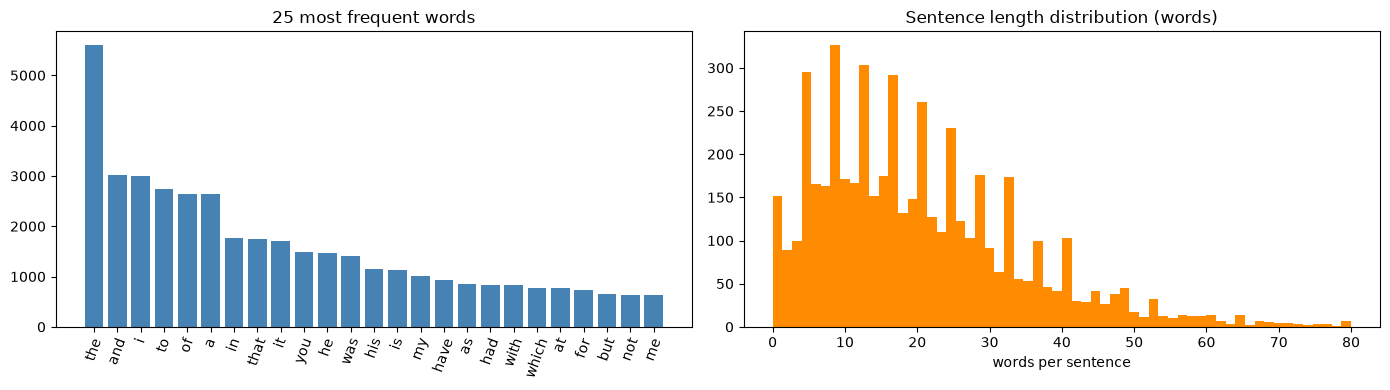

Frequent content words: [('that', 1744), ('have', 924), ('with', 828), ('which', 771), ('there', 503), ('from', 497), ('this', 488), ('said', 486), ('upon', 465), ('holmes', 444), ('very', 400), ('your', 396), ('been', 393), ('what', 387), ('then', 367)]


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
top = lower_counts.most_common(25)
ax[0].bar([w for w, _ in top], [c for _, c in top], color="steelblue")
ax[0].set_title("25 most frequent words"); ax[0].tick_params(axis="x", rotation=70)
sent_lens = [len(re.findall(r"[A-Za-z’']+", s)) for s in sentences]
ax[1].hist(sent_lens, bins=60, range=(0, 80), color="darkorange")
ax[1].set_title("Sentence length distribution (words)"); ax[1].set_xlabel("words per sentence")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/dataset_overview.png", dpi=120); plt.show()

content = [(w, c) for w, c in lower_counts.most_common(300) if len(w) > 3][:15]
print("Frequent content words:", content)

**Dataset characteristics.** The corpus is a collection of 12 short detective stories (1892) narrated in the first
person by Dr. Watson. It is Victorian English prose with long sentences, much dialogue (quotation marks, *“said he”*),
a recurring cast (Holmes, Watson, Lestrade) and a rich, archaic vocabulary. With roughly 100k words it is small by
language-modelling standards, and the vocabulary has a long Zipfian tail (many words occur once), which makes
next-word prediction hard and motivates mapping rare words to `<unk>`.

## 3. Pre-processing, vocabulary and input → target sequences

In [5]:
def clean_text(t):
    t = t.lower()
    t = t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    t = re.sub(r"[—–-]+", " ", t)          # dashes -> space
    t = re.sub(r"_", "", t)                # _italic_ markers
    return t

TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[.,!?;]")   # words (with contractions) + key punctuation
tokens = TOKEN_RE.findall(clean_text(book))
print("Total tokens:", len(tokens))
print(tokens[:40])

Total tokens: 120264
['to', 'sherlock', 'holmes', 'she', 'is', 'always', 'the', 'woman', '.', 'i', 'have', 'seldom', 'heard', 'him', 'mention', 'her', 'under', 'any', 'other', 'name', '.', 'in', 'his', 'eyes', 'she', 'eclipses', 'and', 'predominates', 'the', 'whole', 'of', 'her', 'sex', '.', 'it', 'was', 'not', 'that', 'he', 'felt']


In [6]:
counts = collections.Counter(tokens)
PAD, UNK = "<pad>", "<unk>"
vocab = [PAD, UNK] + [w for w, c in counts.most_common() if c >= MIN_FREQ]
word2id = {w: i for i, w in enumerate(vocab)}
id2word = np.array(vocab)
VOCAB_SIZE = len(vocab)

ids = np.array([word2id.get(w, 1) for w in tokens], dtype=np.int32)
print(f"Vocabulary size: {VOCAB_SIZE}  (words with freq >= {MIN_FREQ}, + <pad>, <unk>)")
print(f"<unk> rate: {(ids == 1).mean():.2%} of tokens")

Vocabulary size: 4418  (words with freq >= 2, + <pad>, <unk>)
<unk> rate: 2.93% of tokens


**Input → target construction.** A sliding window of `SEQ_LEN + 1` tokens is moved over the token stream (stride 1):
the first `SEQ_LEN` tokens are the input and the last token is the target (next word). To avoid leakage between
overlapping windows, the token stream is split **contiguously** into 80 % train / 10 % validation / 10 % test
*before* windowing.

In [7]:
def make_windows(arr):
    w = np.lib.stride_tricks.sliding_window_view(arr, SEQ_LEN + 1)
    return w[:, :-1].copy(), w[:, -1].copy()

n = len(ids); a, b = int(0.8 * n), int(0.9 * n)
X_train, y_train = make_windows(ids[:a])
X_val,   y_val   = make_windows(ids[a:b])
X_test,  y_test  = make_windows(ids[b:])
print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)

for i in range(0, 15, 5):
    print(" ".join(id2word[X_train[i]]), " --> ", id2word[y_train[i]])

train (96201, 10) val (12016, 10) test (12017, 10)
to sherlock holmes she is always the woman . i  -->  have
always the woman . i have seldom heard him mention  -->  her
have seldom heard him mention her under any other name  -->  .


## 4. Models
All four models share **the same** embedding layer, hidden size, dropout, output layer, optimiser, loss, batch size,
sequence length, epoch budget and early-stopping rule — only the recurrent layer changes:

| Model | Architecture |
|---|---|
| Simple RNN | Embedding(100) → SimpleRNN(256) → Dropout(0.2) → Dense(V, softmax) |
| Bidirectional RNN | Embedding(100) → Bidirectional(SimpleRNN(256)) → Dropout(0.2) → Dense(V, softmax) |
| LSTM | Embedding(100) → LSTM(256) → Dropout(0.2) → Dense(V, softmax) |
| GRU | Embedding(100) → GRU(256) → Dropout(0.2) → Dense(V, softmax) |

*Note on the Bidirectional RNN:* the bidirectional layer only reads **within the input window** (the 10 context words)
in both directions; the target word is never visible, so the model is still a valid autoregressive next-word predictor.

In [8]:
def build_model(kind):
    rnn = {
        "SimpleRNN": lambda: layers.SimpleRNN(UNITS),
        "BiRNN":     lambda: layers.Bidirectional(layers.SimpleRNN(UNITS)),
        "LSTM":      lambda: layers.LSTM(UNITS),
        "GRU":       lambda: layers.GRU(UNITS),
    }[kind]
    model = keras.Sequential([
        keras.Input(shape=(SEQ_LEN,), dtype="int32"),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM),
        rnn(),
        layers.Dropout(DROPOUT),
        layers.Dense(VOCAB_SIZE, activation="softmax"),
    ], name=kind)
    model.compile(optimizer=keras.optimizers.Adam(LR),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_acc")])
    return model

MODEL_KINDS = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
for k in MODEL_KINDS:
    build_model(k).summary()

Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 100)        │       441,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 256)            │        91,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4418)           │     1,135,426 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,668,618 (6.37 MB)

 Trainable params: 1,668,618 (6.37 MB)

 Non-trainable params: 0 (0.00 B)

...

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 10, 100)        │       441,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 256)            │       274,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4418)           │     1,135,426 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,852,170 (7.07 MB)

 Trainable params: 1,852,170 (7.07 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Training and quantitative evaluation

In [9]:
histories, results, models = {}, [], {}
for kind in MODEL_KINDS:
    keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    model = build_model(kind)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    print(f"\n===== Training {kind} =====")
    t0 = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=MAX_EPOCHS,
                  batch_size=BATCH_SIZE, callbacks=[es], verbose=2)
    train_time = time.time() - t0
    best = int(np.argmin(h.history["val_loss"]))
    test_loss, test_acc, test_top5 = model.evaluate(X_test, y_test, batch_size=512, verbose=0)
    results.append({
        "Model": kind, "Params": model.count_params(),
        "Epochs run": len(h.history["loss"]), "Best epoch": best + 1,
        "Train loss": h.history["loss"][best], "Val loss": h.history["val_loss"][best],
        "Test loss": test_loss, "Train PPL": math.exp(h.history["loss"][best]),
        "Val PPL": math.exp(h.history["val_loss"][best]), "Test PPL": math.exp(test_loss),
        "Train acc": h.history["accuracy"][best], "Val acc": h.history["val_accuracy"][best],
        "Test acc": test_acc, "Test top-5 acc": test_top5,
        "Train time (s)": train_time, "Time / epoch (s)": train_time / len(h.history["loss"]),
    })
    histories[kind] = h.history; models[kind] = model
    model.save(f"{MODELS_DIR}/{kind}.keras")
    print(f"{kind}: test loss {test_loss:.3f} | test PPL {math.exp(test_loss):.1f} | test acc {test_acc:.3f} | {train_time:.0f}s")

json.dump(histories, open(f"{RESULTS_DIR}/training_histories.json", "w"))
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4).to_csv(f"{RESULTS_DIR}/model_comparison.csv")
results_df.round(3)


===== Training SimpleRNN =====
Epoch 1/30


752/752 - 29s - 39ms/step - accuracy: 0.0983 - loss: 5.7241 - top5_acc: 0.2723 - val_accuracy: 0.1328 - val_loss: 5.2930 - val_top5_acc: 0.3303


Epoch 2/30


752/752 - 32s - 42ms/step - accuracy: 0.1499 - loss: 5.0108 - top5_acc: 0.3574 - val_accuracy: 0.1505 - val_loss: 5.1078 - val_top5_acc: 0.3602


Epoch 3/30


...

752/752 - 60s - 80ms/step - accuracy: 0.2275 - loss: 3.8947 - top5_acc: 0.4663 - val_accuracy: 0.1744 - val_loss: 4.9818 - val_top5_acc: 0.3957


Epoch 7/30


752/752 - 57s - 75ms/step - accuracy: 0.2436 - loss: 3.6779 - top5_acc: 0.4965 - val_accuracy: 0.1736 - val_loss: 5.0318 - val_top5_acc: 0.3930


GRU: test loss 4.904 | test PPL 134.8 | test acc 0.186 | 408s


,Params,Epochs run,Best epoch,Train loss,Val loss,Test loss,Train PPL,Val PPL,Test PPL,Train acc,Val acc,Test acc,Test top-5 acc,Train time (s),Time / epoch (s)
Model,,,,,,,,,,,,,,,
SimpleRNN,1668618,6,3,4.686,5.051,5.059,108.423,156.245,157.480,0.170,0.156,0.168,0.372,203.083,33.847
BiRNN,2891018,5,2,4.966,5.173,5.175,143.427,176.508,176.786,0.151,0.149,0.159,0.353,274.396,54.879
LSTM,1942794,9,6,4.352,4.998,4.996,77.666,148.046,147.856,0.191,0.171,0.184,0.393,576.086,64.010
GRU,1852170,7,4,4.355,4.915,4.904,77.853,136.264,134.829,0.198,0.172,0.186,0.400,407.708,58.244


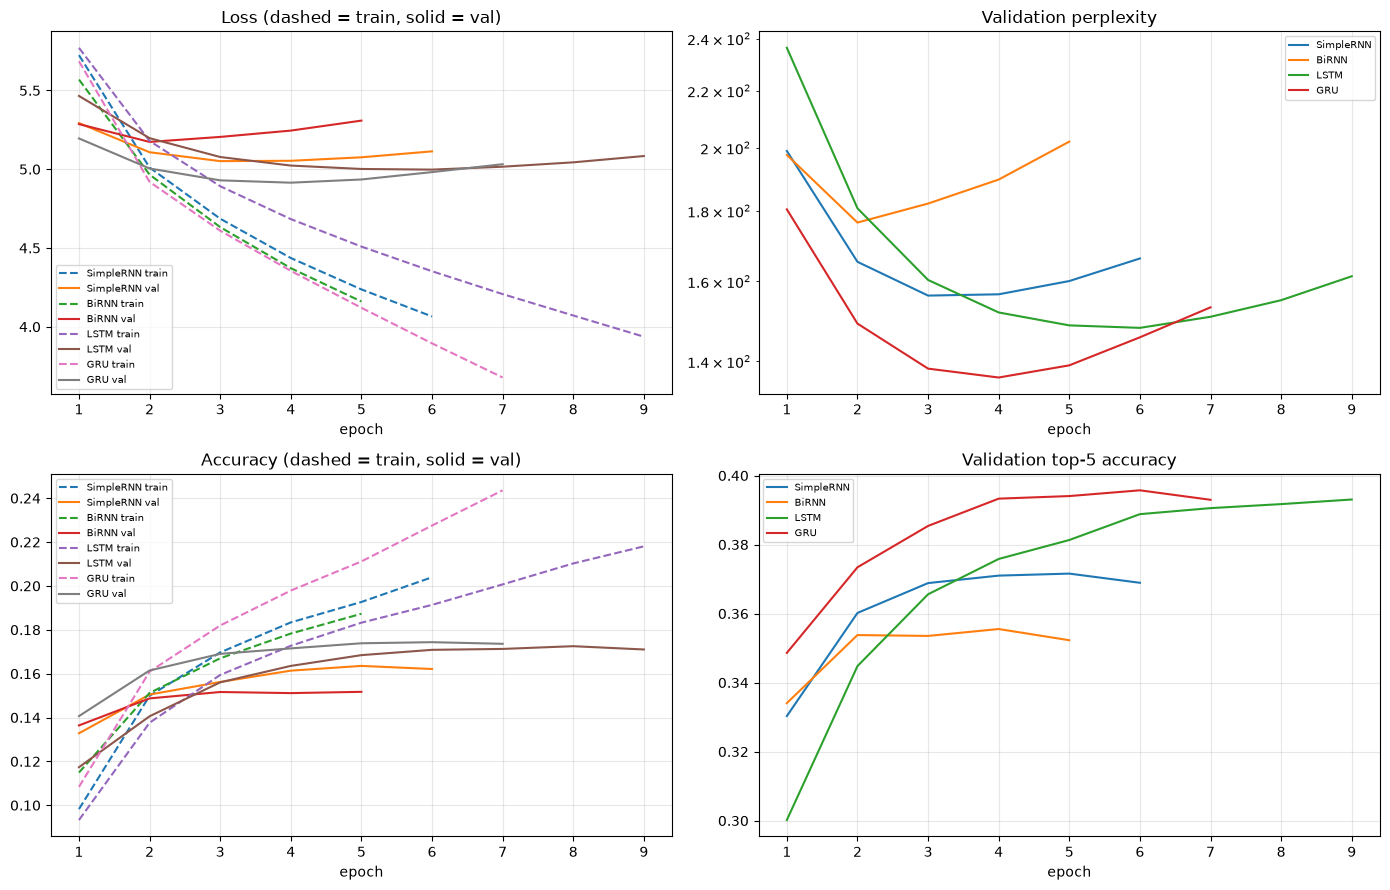

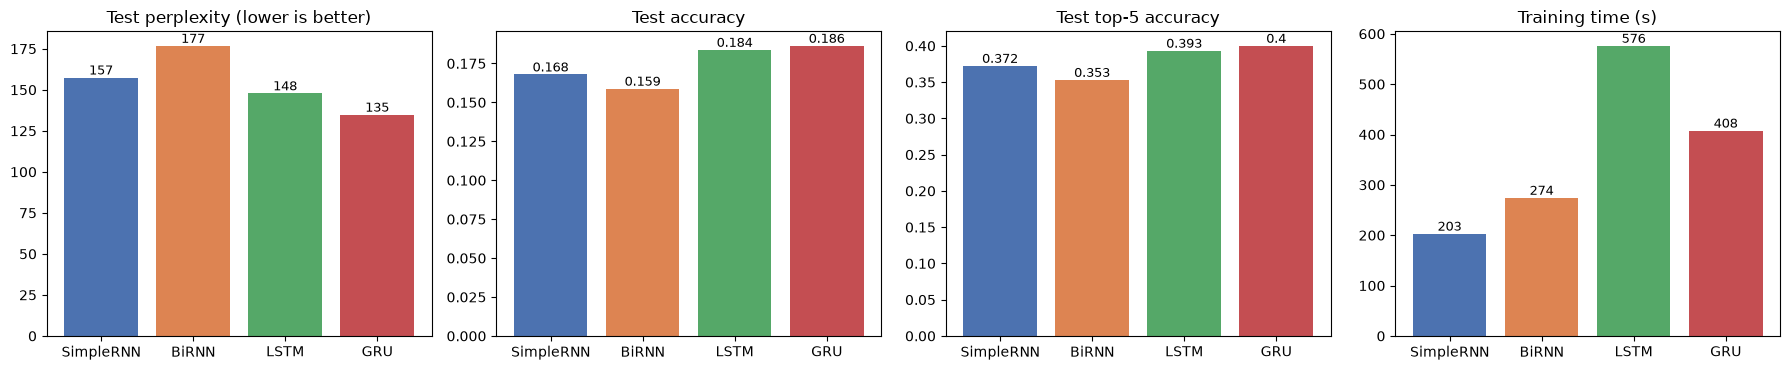

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for kind, h in histories.items():
    ep = range(1, len(h["loss"]) + 1)
    ax[0, 0].plot(ep, h["loss"], "--", label=f"{kind} train"); ax[0, 0].plot(ep, h["val_loss"], label=f"{kind} val")
    ax[0, 1].plot(ep, np.exp(h["val_loss"]), label=kind)
    ax[1, 0].plot(ep, h["accuracy"], "--", label=f"{kind} train"); ax[1, 0].plot(ep, h["val_accuracy"], label=f"{kind} val")
    ax[1, 1].plot(ep, h["val_top5_acc"], label=kind)
for a_, t in zip(ax.flat, ["Loss (dashed = train, solid = val)", "Validation perplexity",
                           "Accuracy (dashed = train, solid = val)", "Validation top-5 accuracy"]):
    a_.set_title(t); a_.set_xlabel("epoch"); a_.legend(fontsize=7); a_.grid(alpha=.3)
ax[0, 1].set_yscale("log")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/training_curves.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
colors = ["#4c72b0", "#dd8452", "#55a868", "#c44e52"]
for a_, col, t in zip(ax, ["Test PPL", "Test acc", "Test top-5 acc", "Train time (s)"],
                      ["Test perplexity (lower is better)", "Test accuracy", "Test top-5 accuracy", "Training time (s)"]):
    vals = results_df[col]; a_.bar(vals.index, vals.values, color=colors); a_.set_title(t)
    for i, v in enumerate(vals.values): a_.text(i, v, f"{v:.3g}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/model_comparison.png", dpi=120); plt.show()

## 6. Autoregressive generation with temperature sampling
At each step the model outputs a distribution *p* over the vocabulary for the next word given the last `SEQ_LEN`
tokens. With temperature *T* the distribution is re-scaled as

$$p_T(w) = \frac{\exp(\log p(w)/T)}{\sum_{w'} \exp(\log p(w')/T)}$$

a word is sampled, appended to the context, and the process repeats. Low *T* sharpens the distribution (close to
greedy decoding), high *T* flattens it. `<pad>`/`<unk>` are never sampled. All models use the **same seeds** and the
**same random state** for a given (seed, temperature, sample) so the comparison is fair.

In [11]:
SEEDS = [
    "it was a cold and foggy morning when sherlock holmes",
    "i had called upon my friend , and found him",
    "the lady had come to us in the greatest distress , for",
]
TEMPERATURES = [0.2, 0.5, 1.0, 1.5]
N_WORDS, N_SAMPLES = 40, 5

def encode(text): return [word2id.get(w, 1) for w in TOKEN_RE.findall(clean_text(text))]
def detok(toks, capitalise_start=True):
    s = " ".join(toks)
    s = re.sub(r" ([.,!?;])", r"\1", s)
    s = re.sub(r"(^|[.!?] )([a-z])" if capitalise_start else r"([.!?] )([a-z])", lambda m: m.group(1) + m.group(2).upper(), s)
    return re.sub(r"\bi\b", "I", s)

def generate_batch(model, seed_text, temperature, n_words=N_WORDS, n_samples=N_SAMPLES, rng_seed=0):
    rng = np.random.default_rng(rng_seed)
    ctx = np.array([encode(seed_text)] * n_samples, dtype=np.int32)
    out = []
    for _ in range(n_words):
        x = ctx[:, -SEQ_LEN:]
        if x.shape[1] < SEQ_LEN: x = np.pad(x, ((0, 0), (SEQ_LEN - x.shape[1], 0)))
        p = model(x, training=False).numpy().astype(np.float64)
        p[:, :2] = 0                                   # never emit <pad>/<unk>
        logp = np.log(p + 1e-12) / temperature
        logp -= logp.max(axis=1, keepdims=True)
        q = np.exp(logp); q /= q.sum(axis=1, keepdims=True)
        nxt = np.array([rng.choice(VOCAB_SIZE, p=qi) for qi in q], dtype=np.int32)
        ctx = np.concatenate([ctx, nxt[:, None]], axis=1); out.append(nxt)
    return [list(id2word[row]) for row in np.stack(out, axis=1)]

generations = []   # one row per (model, seed, temperature, sample)
for kind in MODEL_KINDS:
    for si, seed_text in enumerate(SEEDS):
        for T in TEMPERATURES:
            for j, g in enumerate(generate_batch(models[kind], seed_text, T, rng_seed=1000 * si + int(T * 10))):
                generations.append({"Model": kind, "Seed": si + 1, "Seed text": seed_text,
                                    "Temperature": T, "Sample": j + 1, "tokens": g})
print(len(generations), "generations")

240 generations


In [12]:
with open(f"{RESULTS_DIR}/generated_samples.txt", "w", encoding="utf-8") as f:
    f.write(f"Generated text — {N_WORDS} words per sample, {N_SAMPLES} samples per (model, seed, temperature)\n")
    for si, seed_text in enumerate(SEEDS):
        f.write("\n" + "=" * 100 + f"\nSEED {si+1}: \"{seed_text}\"\n" + "=" * 100 + "\n")
        for T in TEMPERATURES:
            f.write(f"\n--- Temperature {T} ---\n")
            for kind in MODEL_KINDS:
                rows = [g for g in generations if g["Model"] == kind and g["Seed"] == si + 1 and g["Temperature"] == T]
                for g in rows:
                    f.write(f"[{kind:9s} #{g['Sample']}] {detok(seed_text.split())} >> {detok(g['tokens'], False)}\n")

# Show the first sample of every model for every seed/temperature
for si, seed_text in enumerate(SEEDS):
    print("\n" + "=" * 110 + f"\nSEED {si+1}: {seed_text}\n" + "=" * 110)
    for T in TEMPERATURES:
        print(f"\n  T = {T}")
        for kind in MODEL_KINDS:
            g = next(g for g in generations if g["Model"] == kind and g["Seed"] == si + 1 and g["Temperature"] == T)
            print(f"   {kind:9s}: {detok(g['tokens'], False)}")


SEED 1: it was a cold and foggy morning when sherlock holmes

  T = 0.2
   SimpleRNN: , said holmes, said holmes, and I have been aware that I have been to the minute of the parish. I was afraid that I have not be to the best, and I have been in
   BiRNN    : , and I have been lying to the room. I had not be in the room. But I have been to be in the matter. I have been a little thing, and I have been in
   LSTM     : , and I have a little man, and the little man is a little man, and a man was a little man, and a little man was a little man. I have a little man,
   GRU      : was a little man, and I have no doubt that you have been able to be a little of the matter, and I have heard that the matter is a little man. I have been able to

  T = 0.5
   SimpleRNN: was a good room. He was a little man, but I had been fallen. Holmes, and at the door of the parish, and I had been to the floor. This, I am not
   BiRNN    : was a little street, which was a little man, or as a little goose, said 

## 7. Generation-quality metrics and temperature analysis
Qualitative properties are quantified with simple, reproducible proxies computed on all generated samples:

| Property | Metric | Interpretation |
|---|---|---|
| **Coherence** | *Bigram plausibility* — % of generated bigrams (incl. the seed→continuation junction) that occur in the training text | higher = more locally fluent / grammatical |
| **Coherence** | *Reference perplexity* — perplexity of the generated text under an independent smoothed bigram LM fitted on the training text | lower = more natural word sequences |
| **Diversity** | *distinct-1 / distinct-2* — unique unigrams / bigrams ÷ total, computed per sample | higher = more varied |
| **Repetition** | *repeated-trigram rate* — 1 − unique trigrams ÷ total trigrams, per sample | higher = more looping |
| **Contextual consistency** | cosine similarity between the seed and the continuation in a shared PPMI-SVD word-embedding space built from the training text | higher = continuation stays on the seed's topic |

In [13]:
from scipy.sparse import coo_matrix
from sklearn.decomposition import TruncatedSVD

train_ids = ids[:a]
train_bigrams = set(zip(train_ids[:-1].tolist(), train_ids[1:].tolist()))

# Independent reference bigram LM (add-k smoothing) for "reference perplexity"
uni = np.bincount(train_ids, minlength=VOCAB_SIZE).astype(np.float64)
big = collections.Counter(zip(train_ids[:-1].tolist(), train_ids[1:].tolist()))
K_SMOOTH = 0.1
def ref_ppl(id_seq):
    lp = [math.log((big.get((u, v), 0) + K_SMOOTH) / (uni[u] + K_SMOOTH * VOCAB_SIZE)) for u, v in zip(id_seq[:-1], id_seq[1:])]
    return math.exp(-np.mean(lp))

# Shared PPMI-SVD embedding (window 4) for contextual consistency
rows, cols = [], []
for k in range(1, 5):
    rows += [train_ids[:-k], train_ids[k:]]; cols += [train_ids[k:], train_ids[:-k]]
C = coo_matrix((np.ones(sum(len(r) for r in rows)), (np.concatenate(rows), np.concatenate(cols))),
               shape=(VOCAB_SIZE, VOCAB_SIZE)).tocsr()
tot = C.sum(); rs = np.asarray(C.sum(1)).ravel(); cs = np.asarray(C.sum(0)).ravel() ** 0.75; cs = cs / cs.sum()
C = C.tocoo()
pmi = np.log((C.data / tot) / ((rs[C.row] / tot) * cs[C.col]))
keep = pmi > 0
PPMI = coo_matrix((pmi[keep], (C.row[keep], C.col[keep])), shape=C.shape).tocsr()
E = TruncatedSVD(100, random_state=SEED).fit_transform(PPMI)
E /= np.linalg.norm(E, axis=1, keepdims=True) + 1e-9
STOP = {word2id[w] for w in ["the", "a", "an", "and", "of", "to", "in", ",", ".", "?", "!", ";", "i", "he", "it", "was", "that", "is", "his", "you", "my", "as", "had", "with", "at", "for", "which", "but", "be", "have", "me", "him", "not", "this", "on", "she", "her", "said", "from", "so", "there", "we", "by", "all", "were", "upon", "one", "been", "or", "they", "what"] if w in word2id}
def mean_vec(id_seq):
    v = [E[i] for i in id_seq if i not in STOP and i > 1]
    return np.mean(v, axis=0) if v else np.zeros(E.shape[1])
def cos(u, v): return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v) + 1e-9))

def ngrams(seq, n): return list(zip(*[seq[i:] for i in range(n)]))
for g in generations:
    seed_ids, gen_ids = encode(g["Seed text"]), [word2id[w] for w in g["tokens"]]
    full = seed_ids[-1:] + gen_ids
    bg, tg = ngrams(gen_ids, 2), ngrams(gen_ids, 3)
    g["Bigram plausibility"] = np.mean([b in train_bigrams for b in ngrams(full, 2)])
    g["Reference PPL"] = ref_ppl(full)
    g["Distinct-1"] = len(set(gen_ids)) / len(gen_ids)
    g["Distinct-2"] = len(set(bg)) / len(bg)
    g["Repetition (trigram)"] = 1 - len(set(tg)) / len(tg)
    g["Context consistency"] = cos(mean_vec(seed_ids), mean_vec(gen_ids))

gen_df = pd.DataFrame(generations)
gen_df.assign(text=gen_df["tokens"].map(detok)).drop(columns="tokens").to_csv(f"{RESULTS_DIR}/generations_all.csv", index=False)
METRICS = ["Bigram plausibility", "Reference PPL", "Distinct-1", "Distinct-2", "Repetition (trigram)", "Context consistency"]
by_mt = gen_df.groupby(["Model", "Temperature"])[METRICS].mean().round(3)
by_mt.to_csv(f"{RESULTS_DIR}/generation_metrics_by_model_temperature.csv")
by_mt

Bigram plausibility  Reference PPL  Distinct-1  \
Model     Temperature                                                   
BiRNN     0.2                        0.983         29.098       0.458   
          0.5                        0.902         71.694       0.625   
          1.0                        0.607        592.383       0.830   
          1.5                        0.268       2538.042       0.933   
GRU       0.2                        0.963         42.272       0.472   
          0.5                        0.928         67.133       0.678   
          1.0                        0.668        422.280       0.825   
          1.5                        0.288       2373.485       0.945   
LSTM      0.2                        1.000         31.403       0.322   
          0.5                        0.918         69.732       0.633   
          1.0                        0.650        540.178       0.825   
          1.5                        0.313       2209.798       0.918   
SimpleRNN 0.2                        0.970         38.181       0.442   
          0.5                        0.923         62.839       0.647   
          1.0                        0.595        599.132       0.812   
          1.5                        0.235       2814.122       0.935   

                       Distinct-2  Repetition (trigram)  Context consistency  
Model     Temperature                                                         
BiRNN     0.2               0.677                 0.175                0.627  
          0.5               0.885                 0.025                0.687  
          1.0               0.993                 0.000                0.714  
          1.5               0.998                 0.000                0.717  
GRU       0.2               0.679                 0.186                0.622  
          0.5               0.925                 0.014                0.689  
          1.0               0.997                 0.000                0.729  
          1.5               0.998                 0.000                0.722  
LSTM      0.2               0.492                 0.372                0.598  
          0.5               0.887                 0.021                0.681  
          1.0               0.993                 0.000                0.712  
          1.5               0.997                 0.000                0.736  
SimpleRNN 0.2               0.615                 0.275                0.608  
          0.5               0.894                 0.016                0.710  
          1.0               0.986                 0.000                0.729  
          1.5               1.000                 0.000                0.715

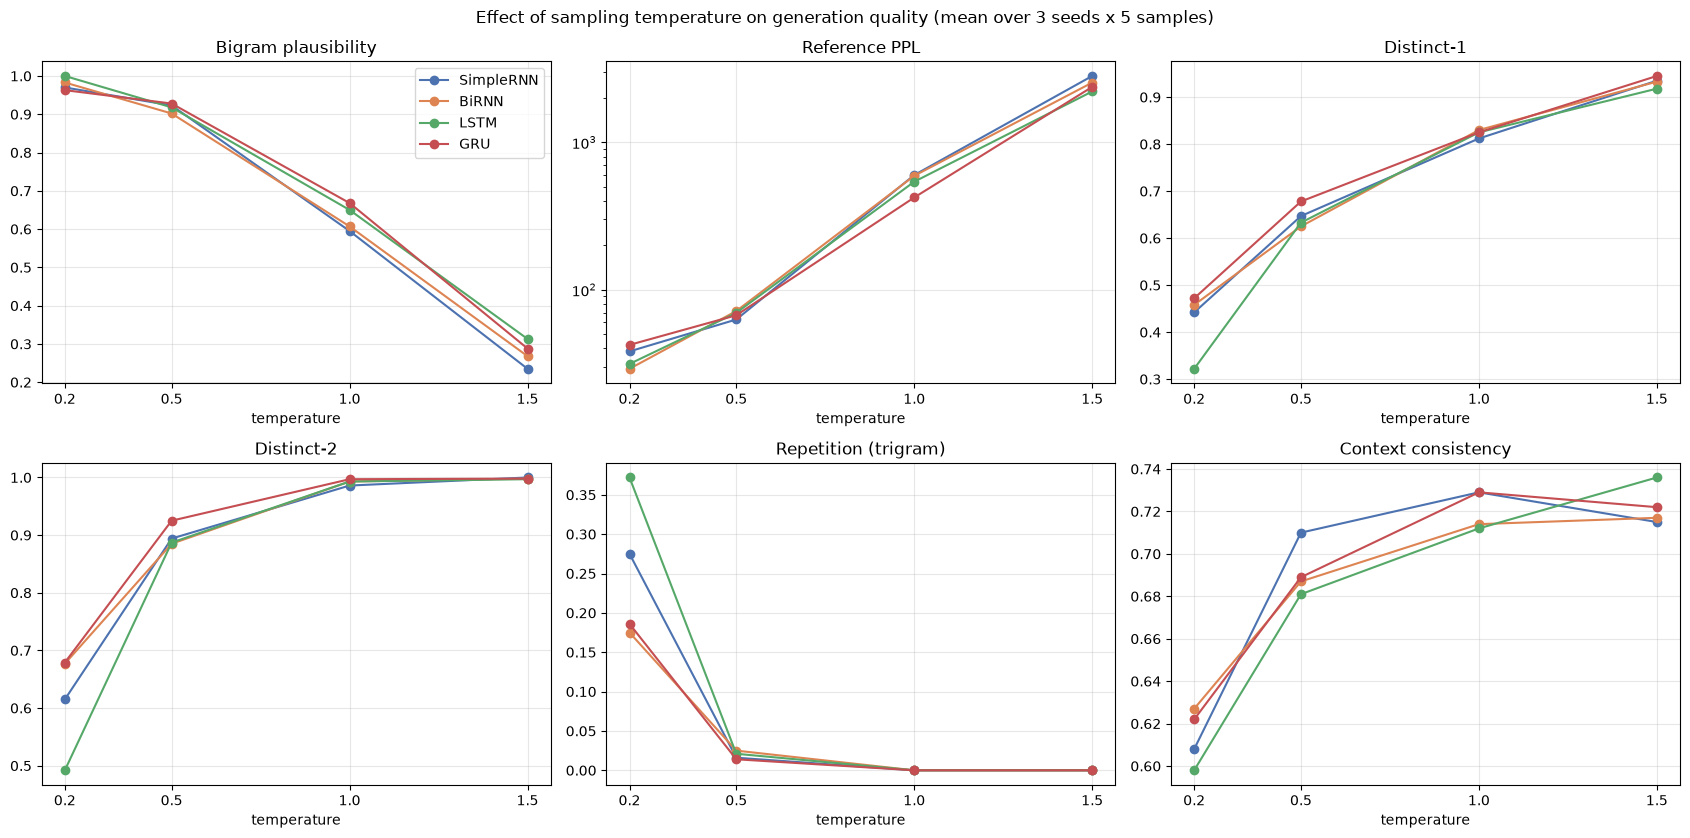

In [14]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
for a_, m in zip(ax.flat, METRICS):
    for kind, col in zip(MODEL_KINDS, colors):
        s = by_mt.loc[kind][m]; a_.plot(s.index, s.values, "o-", label=kind, color=col)
    a_.set_title(m); a_.set_xlabel("temperature"); a_.set_xticks(TEMPERATURES); a_.grid(alpha=.3)
ax[0, 1].set_yscale("log"); ax[0, 0].legend()
plt.suptitle("Effect of sampling temperature on generation quality (mean over 3 seeds x 5 samples)")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/temperature_analysis.png", dpi=120); plt.show()

### Overall ranking
To pick the best model for autoregressive generation, the quantitative test metrics are combined with the generation
metrics at the moderate temperatures that are actually useful in practice (T = 0.5 and T = 1.0).

In [15]:
mid = gen_df[gen_df.Temperature.isin([0.5, 1.0])].groupby("Model")[METRICS].mean()
summary = results_df[["Test PPL", "Test acc", "Test top-5 acc", "Train time (s)", "Params"]].join(mid).loc[MODEL_KINDS]
higher_better = {"Test acc", "Test top-5 acc", "Bigram plausibility", "Distinct-1", "Distinct-2", "Context consistency"}
rank_cols = ["Test PPL", "Test acc", "Test top-5 acc", "Bigram plausibility", "Reference PPL", "Distinct-2", "Repetition (trigram)", "Context consistency"]
ranks = pd.DataFrame({c: summary[c].rank(ascending=c not in higher_better) for c in rank_cols})
summary["Mean rank (lower = better)"] = ranks.mean(axis=1)
summary = summary.sort_values("Mean rank (lower = better)")
summary.round(3).to_csv(f"{RESULTS_DIR}/overall_summary.csv")
print("Best model by mean rank:", summary.index[0])
summary.round(3)

Best model by mean rank: GRU


,Test PPL,Test acc,Test top-5 acc,Train time (s),Params,Bigram plausibility,Reference PPL,Distinct-1,Distinct-2,Repetition (trigram),Context consistency,Mean rank (lower = better)
Model,,,,,,,,,,,,
GRU,134.829,0.186,0.400,407.708,1852170,0.798,244.706,0.752,0.961,0.007,0.709,1.125
LSTM,147.856,0.184,0.393,576.086,1942794,0.784,304.955,0.729,0.940,0.011,0.696,2.438
SimpleRNN,157.480,0.168,0.372,203.083,1668618,0.759,330.985,0.729,0.940,0.008,0.719,2.562
BiRNN,176.786,0.159,0.353,274.396,2891018,0.754,332.039,0.727,0.939,0.012,0.700,3.875



## 8. Analysis and conclusion

### Quantitative comparison (test set, best epoch restored by early stopping)
| Model | Params | Best epoch | Test loss | Test PPL ↓ | Test acc ↑ | Top-5 acc ↑ | Train time (s) | s / epoch |
|---|---|---|---|---|---|---|---|---|
| Simple RNN | 1.67 M | 3 | 5.059 | 157.5 | 16.8 % | 37.2 % | 203 | 33.8 |
| Bidirectional RNN | 2.89 M | 2 | 5.175 | 176.8 | 15.9 % | 35.3 % | 274 | 54.9 |
| LSTM | 1.94 M | 6 | 4.996 | 147.9 | 18.4 % | 39.3 % | 576 | 64.0 |
| **GRU** | 1.85 M | 4 | **4.904** | **134.8** | **18.6 %** | **40.0 %** | 408 | 58.2 |

* **GRU** has the lowest test perplexity and the highest top-1 and top-5 accuracy. **LSTM** comes second: it learns more slowly (lowest validation loss at epoch 6) but generalises well. Both gated models clearly beat the vanilla RNNs.
* **Simple RNN** trains fastest per epoch, but it starts to overfit after epoch 3. Its plain tanh recurrence also loses information over the 10-word window (vanishing gradients).
* **Bidirectional RNN** has the most parameters, but it overfits fastest (best epoch 2) and gets the *worst* perplexity. The backward pass over a 10-word context adds capacity but no useful information for predicting the *next* word. At generation time only the left context exists, so bidirectionality is not suited to autoregressive modelling.
* All models overfit this small (≈120 k tokens) corpus within a few epochs: training loss keeps falling while validation loss rises. Early stopping with best-weight restoration was essential.

### Temperature analysis (means over 3 seeds × 5 samples × 40 words)
* **T = 0.2 (near-greedy):** the output is very locally fluent (96–100 % of bigrams occur in the training text, reference PPL ≈ 30–40), but it degenerates into loops such as *“a little man, and a little man …”* and *“of the parish of the parish …”*. Repeated-trigram rate reaches 18–37 % and distinct-2 is only 0.49–0.68. The LSTM is the most repetitive here.
* **T = 0.5:** this is the best trade-off. Fluency stays high (≈ 90–93 % plausible bigrams), repetition almost disappears (1–2.5 %), and diversity rises sharply (distinct-2 ≈ 0.89–0.93). The text reads like Holmes-style narration: *“…, mr. Hudson, my stepfather, and I have a card of the police.”*
* **T = 1.0:** the text becomes much more varied (distinct-2 ≈ 0.99) and uses rarer vocabulary. Grammaticality drops, though: only 60–67 % plausible bigrams, and reference PPL rises about tenfold.
* **T = 1.5:** the output is close to a random bag of words (≈ 25–30 % plausible bigrams, reference PPL > 2000). It has maximal diversity and no repetition, but no coherence.
* So higher temperature gives **more diversity and less repetition, at the cost of coherence**. The *context-consistency* proxy (seed–continuation cosine in a PPMI space) rises only mildly with T. Once the text is fragmented, it mostly reflects general topical vocabulary, so it was weighted together with the other measures and not on its own.

### Best model
**GRU gives the most effective autoregressive generation for this dataset.** It has the best test perplexity (134.8), the best accuracy (18.6 % top-1 / 40.0 % top-5), and the best mean rank across all quantitative and generation metrics (1.1, against 2.4 for LSTM, 2.6 for Simple RNN and 3.9 for Bi-RNN). At the useful temperatures (0.5–1.0) it has the highest bigram plausibility, the lowest reference perplexity and the highest diversity with the least repetition. It also trains about 30 % faster than the LSTM with fewer parameters. LSTM is a close second. The recommended setting is **GRU with T ≈ 0.5–0.7**.
